<a href="https://colab.research.google.com/github/Business-Intelligence-Book/business-intelligence-book.github.io/blob/main/labs/07-regression-2/walkthrough/walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2F5597"><span style="background:#2F5597;color:#fff;padding:2px 10px;border-radius:3px">Lab 07</span>&nbsp; Regression II</h1>

<p style="color:#595959"><b style="color:#C55A11">Walkthrough</b> · Categorical variables, polynomial regression and overfitting · <i>Business Intelligence and Analytics</i> · Chapter 7</p>

<div style="background:#FFF2CC;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#C55A11">💡 What you will learn this week</b></p>
<ul style="margin:0">
<li>How to use categorical variables in a regression: label encoding and one-hot encoding</li>
<li>How polynomial regression fits curved relationships</li>
<li>What overfitting is and how to recognize it</li>
<li>How cross-validation helps to choose a model</li>
</ul>
</div>

Run the cells from top to bottom. Text cells explain each step; code cells show how to do it in Python.

---

# Regression 2

We continue with regression and look at more specific methods: encoding categorical variables (label and one-hot encoding), polynomial regression, overfitting and cross-validation.

<div style="background:#E8EEF7;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#2F5597">⭐ Fun fact: Fitting an elephant</b></p>
The physicist Enrico Fermi liked to quote his colleague John von Neumann on models with too many parameters: "With four parameters I can fit an elephant, and with five I can make him wiggle his trunk." A model that is flexible enough can fit anything, including the noise. That is overfitting.
</div>

# Regression with categorical variables

In [1]:
import matplotlib.pylab as plt
import pandas as pd
import numpy as np

%matplotlib inline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
import seaborn as sns
import statistics

## Load the dataset

The dataset was extracted and modified from [Kaggle](https://www.kaggle.com/mohansacharya/graduate-admissions). It describes students and their chances of admission to a graduate program.

In [2]:
# Load the dataset
url = "https://raw.githubusercontent.com/Business-Intelligence-Book/business-intelligence-book.github.io/main/labs/data/Admissions_prediction.csv"
GAD = pd.read_csv(
    url, sep=";", index_col="Serial No."
).drop_duplicates()  # Graduate Admissions Data

display(GAD.head())
print(GAD.dtypes)
print("Data matrix shape: ", GAD.shape)

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
Serial No.,,,,,,,,
1,337,118,GOOD,4.5,4.5,9.65,YES,0.92
2,324,107,GOOD,4.0,4.5,8.87,YES,0.76
3,316,104,AVERAGE,3.0,3.5,8.00,YES,0.72
4,322,110,AVERAGE,3.5,2.5,8.67,YES,0.80
5,314,103,FAIR,2.0,3.0,8.21,NO,0.65


GRE Score              int64
TOEFL Score            int64
University Rating     object
SOP                  float64
LOR                  float64
CGPA                 float64
Research              object
Chance of Admit      float64
dtype: object
Data matrix shape:  (400, 8)


An overview of the columns:


 * `GRE Score`: GRE, a standardized admission test (out of 340)
 * `TOEFL Score`: knowledge of English (out of 120)
 * `SOP`: statement of purpose (out of 5)
 * `LOR`: letter of recommendation (out of 5)
 * `CGPA`: college GPA (out of 10)
 * `Research`: whether the applicant did research or not


 **We will predict the chance of admission from the other variables.**

## Handling categorical variables for regression

Let's start with the `Research` column. An applicant was either active in research or not, so there are only 2 possible values. We assign 1 to **YES** and 0 to **NO**.

In [3]:
GAD["Research"] = GAD["Research"].map({"NO": 0, "YES": 1})
display(GAD.head())

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
Serial No.,,,,,,,,
1,337,118,GOOD,4.5,4.5,9.65,1,0.92
2,324,107,GOOD,4.0,4.5,8.87,1,0.76
3,316,104,AVERAGE,3.0,3.5,8.00,1,0.72
4,322,110,AVERAGE,3.5,2.5,8.67,1,0.80
5,314,103,FAIR,2.0,3.0,8.21,0,0.65


An alternative is the label encoder:

```python
# Use the label encoder to turn the Research variable into a binary variable
label_encoder = LabelEncoder()

# Fit and transform the data
df['Research'] = label_encoder.fit_transform(df['Research'])
```

Let's get a quick overview of the **correlations** between our variables with a heatmap.

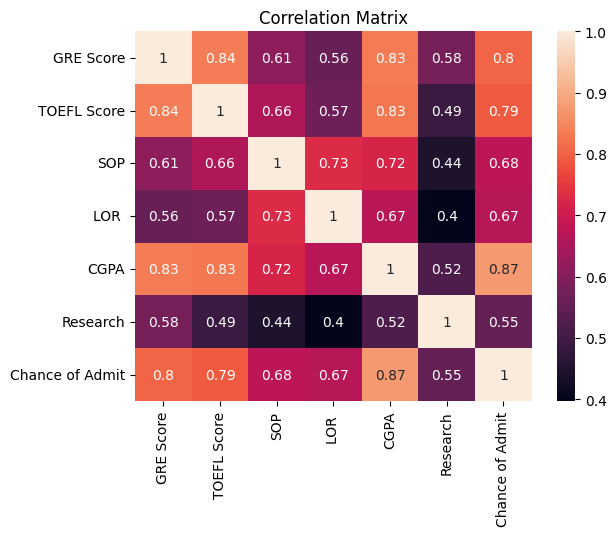

In [4]:
sns.heatmap(GAD.corr(numeric_only=True), annot=True)
plt.title("Correlation Matrix")
plt.show()

We want to predict the **chance of admission** from the other columns, so we create a DataFrame **X** with all the variables except `Chance of Admit`.

In [5]:
# We assign the variable Y to the chance of admission
y = GAD[["Chance of Admit"]]

# We create the dataframe X
X = GAD.drop("Chance of Admit", axis=1)

X.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
Serial No.,,,,,,,
1,337,118,GOOD,4.5,4.5,9.65,1
2,324,107,GOOD,4.0,4.5,8.87,1
3,316,104,AVERAGE,3.0,3.5,8.00,1
4,322,110,AVERAGE,3.5,2.5,8.67,1
5,314,103,FAIR,2.0,3.0,8.21,0


In [6]:
X.dtypes

GRE Score              int64
TOEFL Score            int64
University Rating     object
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
dtype: object

Now we need to handle the `University Rating` column.
We will try both label encoding and one-hot encoding.

For *label encoding*, we use scikit-learn's `LabelEncoder`.

In [7]:
# Creating X_lab for comparison later with X_hot
X_label = X.copy()

# We will use LabelEncoder
label_encoder = LabelEncoder()

# Applying the LabelEncoder to the 'University Rating' column
X_label["University Rating"] = label_encoder.fit_transform(X_label["University Rating"])

In [8]:
display(X_label.head())
display(X_label["University Rating"].unique())

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
Serial No.,,,,,,,
1,337,118,3,4.5,4.5,9.65,1
2,324,107,3,4.0,4.5,8.87,1
3,316,104,0,3.0,3.5,8.00,1
4,322,110,0,3.5,2.5,8.67,1
5,314,103,2,2.0,3.0,8.21,0


array([3, 0, 2, 1, 4])

In [9]:
label_encoder.classes_  # Here we can see that the 0 corresponds to Average, 1 is excellent, 2 Fair, 3 Good and 4 Poor

array(['AVERAGE', 'EXCELLENT', 'FAIR', 'GOOD', 'POOR'], dtype=object)

For *one-hot encoding*, we use the pandas `get_dummies` function.

In [10]:
# 1-hot encoding

# We create a DF with Dummy variables
dummies = pd.get_dummies(GAD["University Rating"])
X_hot = pd.concat(
    [X, dummies], axis=1
)  # We put together the X with the dummy columns we created

# We drop the Rating column
del X_hot["University Rating"]

# Have a look at what dummies actually looks like
display(dummies)
display(X_hot.head())

,AVERAGE,EXCELLENT,FAIR,GOOD,POOR
Serial No.,,,,,
1,False,False,False,True,False
2,False,False,False,True,False
3,True,False,False,False,False
4,True,False,False,False,False
5,False,False,True,False,False
...,...,...,...,...,...
396,True,False,False,False,False
397,True,False,False,False,False
398,False,False,False,True,False


,GRE Score,TOEFL Score,SOP,LOR,CGPA,Research,AVERAGE,EXCELLENT,FAIR,GOOD,POOR
Serial No.,,,,,,,,,,,
1,337,118,4.5,4.5,9.65,1,False,False,False,True,False
2,324,107,4.0,4.5,8.87,1,False,False,False,True,False
3,316,104,3.0,3.5,8.00,1,True,False,False,False,False
4,322,110,3.5,2.5,8.67,1,True,False,False,False,False
5,314,103,2.0,3.0,8.21,0,False,False,True,False,False


We now build two models, one with one-hot encoding and one with label encoding.


Let's start with *label encoding*:

In [11]:
# Split Dataset
X_train_lab, X_test_lab, y_train_lab, y_test_lab = train_test_split(
    X_label, y, test_size=0.2, random_state=0, shuffle=True
)  # Splitting training and testing

# Fit the model
model_lab = LinearRegression()
model_lab.fit(X_train_lab, y_train_lab)  # Fit the model on the training data

# Calculate R2
lab_r2 = round(model_lab.score(X_train_lab, y_train_lab), 4)
print("R^2 of train set using label encoding: ", lab_r2)

# Calculate Scores on Test-Set
label_predictions = model_lab.predict(X_test_lab)
lab_mae = mean_absolute_error(y_test_lab, label_predictions)
lab_mse = mean_squared_error(y_test_lab, label_predictions)
lab_r2_test = r2_score(y_test_lab, label_predictions)

print("MAE LAB %.2f" % lab_mae)
print("MSE LAB %.2f" % lab_mse)
print("R^2 score LAB %.4f" % lab_r2_test)

R^2 of train set using label encoding:  0.8165
MAE LAB 0.05
MSE LAB 0.00
R^2 score LAB 0.7355


And now with *one-hot encoding*:

In [12]:
# Split Dataset
X_train_hot, X_test_hot, y_train_hot, y_test_hot = train_test_split(
    X_hot, y, test_size=0.2, random_state=0, shuffle=True
)

# Fit the model
model_hot = LinearRegression()
model_hot.fit(X_train_hot, y_train_hot)

# Calculate R2
hot_r2 = round(model_hot.score(X_train_hot, y_train_hot), 4)
print("R^2 Train Score using 1-hot encoding : ", hot_r2)

# Calculate Scores on Test-Set
hot_predictions = model_hot.predict(X_test_hot)
hot_mae = mean_absolute_error(y_test_hot, hot_predictions)
hot_mse = mean_squared_error(y_test_hot, hot_predictions)
hot_r2_test = r2_score(y_test_hot, hot_predictions)


print("MAE HOT %.2f" % hot_mae)
print("MSE HOT %.2f" % hot_mse)
print("R^2 score HOT %.4f" % hot_r2_test)

R^2 Train Score using 1-hot encoding :  0.8182
MAE HOT 0.05
MSE HOT 0.00
R^2 score HOT 0.7403


In [13]:
print(
    "The 1-hot encoding method yields an R^2 {}% higher than using label encoding for the train set.".format(
        round((hot_r2 / lab_r2 - 1) * 100, 3)
    )
)

The 1-hot encoding method yields an R^2 0.208% higher than using label encoding for the train set.


In [14]:
print(
    "The 1-hot encoding method yields an R^2 {}% higher than using label encoding for the test set.".format(
        round((hot_r2_test / lab_r2_test - 1) * 100, 3)
    )
)

The 1-hot encoding method yields an R^2 0.65% higher than using label encoding for the test set.


Look at how the **intercepts** and the **coefficients** differ between the two methods:

In [15]:
print("Intercept: ", model_hot.intercept_[0])
print("Intercept: ", model_lab.intercept_[0])

Intercept:  -1.28473852400408
Intercept:  -1.36058128268221


In [16]:
weights_hot = model_hot.coef_.flatten()
weights_lab = model_lab.coef_.flatten()

print("Features coefficients for HOT (weights): ", model_hot.coef_)
print("Features coefficients for LAB (weights): ", model_lab.coef_)

Features coefficients for HOT (weights):  [[ 0.0020506   0.00202487 -0.00418539  0.02129711  0.12447107  0.02416713
  -0.0036891   0.01520818 -0.01014306  0.00121785 -0.00259387]]
Features coefficients for LAB (weights):  [[ 0.0021295   0.00213468  0.00026054 -0.00262146  0.02259374  0.1276427
   0.02445849]]


# Polynomial linear regression

Let's now look at another model. We use the `Advertising` data from the previous lab. The task is to find out how different advertising channels influence the sales of a product.

In [17]:
ad_df = pd.read_csv(
    "https://raw.githubusercontent.com/Business-Intelligence-Book/business-intelligence-book.github.io/main/labs/data/Advertising.csv",
    index_col="id",
)
ad_df.head()

,TV,Radio,Newspaper,Sales
id,,,,
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


As before, we start by defining y and X. The dependent variable is `Sales`, and the independent variables are the advertising channels (`TV`, `Radio` and `Newspaper`).

In [18]:
y = ad_df["Sales"]
X = ad_df.drop("Sales", axis=1)

In [19]:
# First let's go for a linear multivariate regression
# You should know the drill by now
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, shuffle=True
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# 3. Performance metrics
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Test scores: ")
print("MAE %.2f" % mae)
print("MSE %.2f" % mse)
print("R^2 %.2f" % r2)

print("Train metrics")
print("params: ", model.coef_)
print("constant: ", model.intercept_)
print("R^2 score: ", model.score(X, y))

Test scores: 
MAE 1.36
MSE 4.40
R^2 0.86
Train metrics
params:  [ 0.04458402  0.19649703 -0.00278146]
constant:  2.99489303049533
R^2 score:  0.8964076641629949


Polynomial regression fits a curve instead of a straight line, which often improves the model. The function `PolynomialFeatures` generates a new feature matrix with all polynomial combinations of the features up to the specified degree.

For example, if an input sample has two dimensions, [a, b], the degree-2 polynomial features are [1, a, b, a^2, ab, b^2]. Let's try it on our model.

In [20]:
# Polynomial regression
poly = PolynomialFeatures(2)  # We want degree-2 polynomial features
X = np.array(
    ad_df[["TV", "Radio"]]
)  # These are the two features we want to use. We will have in the array : 1 , TV , Radio , TV^2 , TV * Radio , Radio^2
y = np.array(ad_df["Sales"])
X_poly = poly.fit_transform(X)  # Create the polynomial features

In [21]:
X_poly

array([[1.000000e+00, 2.301000e+02, 3.780000e+01, 5.294601e+04,
        8.697780e+03, 1.428840e+03],
       [1.000000e+00, 4.450000e+01, 3.930000e+01, 1.980250e+03,
        1.748850e+03, 1.544490e+03],
       [1.000000e+00, 1.720000e+01, 4.590000e+01, 2.958400e+02,
        7.894800e+02, 2.106810e+03],
       ...,
       [1.000000e+00, 1.770000e+02, 9.300000e+00, 3.132900e+04,
        1.646100e+03, 8.649000e+01],
       [1.000000e+00, 2.836000e+02, 4.200000e+01, 8.042896e+04,
        1.191120e+04, 1.764000e+03],
       [1.000000e+00, 2.321000e+02, 8.600000e+00, 5.387041e+04,
        1.996060e+03, 7.396000e+01]])

In [22]:
LR = LinearRegression(
    fit_intercept=False
)  # We don't need fit intercept since polynomial features function add a column of ones to the data
LR.fit(
    X_poly, y
)  # We make a linear regression of the model which is in the format b0 + b1 TV + b2 Radio + b3 TV^2 + b4 TV*Radio + b5 Radio^2
print("params: ", LR.coef_)
print("R^2 score: ", LR.score(X_poly, y))

params:  [ 5.19444187e+00  5.09930683e-02  2.65400299e-02 -1.09816273e-04
  1.07462080e-03  1.86076136e-04]
R^2 score:  0.986039101078374


## Overfitting
Beware: adding too many features may cause **overfitting**.
Overfitting is the tendency of a model to fit the training data too closely, at the expense of generalization to new data points. We want to avoid it.

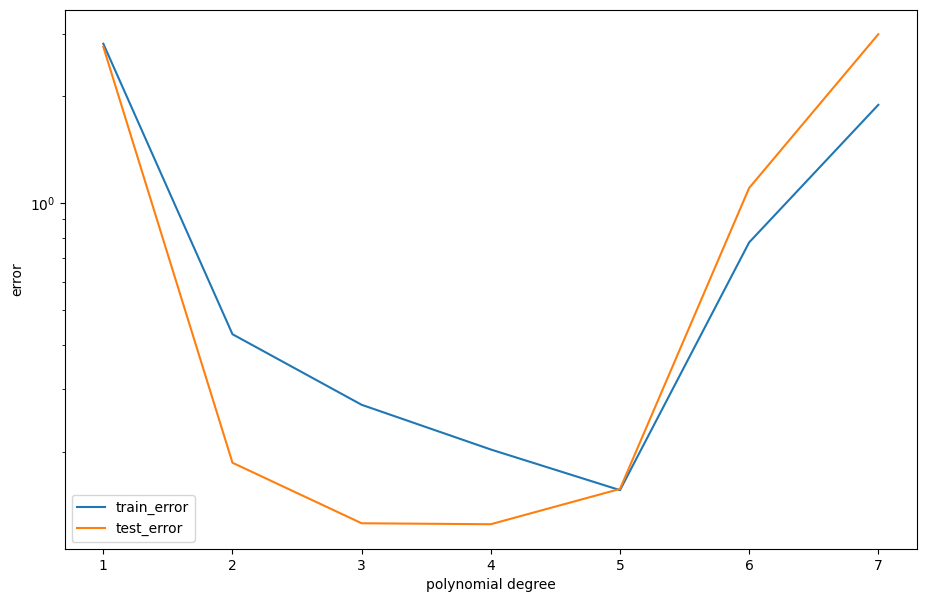

In [23]:
train_err = []
test_err = []
for f in range(1, 8):
    poly = PolynomialFeatures(f)
    X_poly = poly.fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(
        X_poly, y, test_size=0.2, random_state=12
    )
    LR = LinearRegression(fit_intercept=False)
    LR.fit(X_train, y_train)
    train_err.append(mean_squared_error(y_train, LR.predict(X_train)))
    test_err.append(mean_squared_error(y_test, LR.predict(X_test)))


fig = plt.figure(figsize=(11, 7))
plt.plot(range(1, 8), train_err, label="train_error")
plt.plot(range(1, 8), test_err, label="test_error")
plt.legend(fontsize=10)
plt.xlabel("polynomial degree")
plt.yscale(
    "log"
)  # Putting in log scale the y axis because the error skyrockets when having 7 degrees
plt.ylabel("error")
plt.show()

In [24]:
from sklearn.model_selection import KFold

y = ad_df["Sales"]
X = ad_df.drop("Sales", axis=1)

kf = KFold(
    n_splits=10, random_state=None
)  # this means we try 10 different folds, meaning a test size of 10%
model = LinearRegression()

mae_cumm = []
mse_cumm = []
r2_cumm = []

for train_index, test_index in kf.split(
    X
):  # We make for each of the 10 folds the calculations

    X_train, X_test = X.iloc[train_index, :], X.iloc[test_index, :]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    mae_cumm.append(mae)
    mse_cumm.append(mse)
    r2_cumm.append(r2)


mean_mae = sum(mae_cumm) / len(mae_cumm)  # looking at the averages of the 10 folds
mean_mse = sum(mse_cumm) / len(mse_cumm)
mean_r2 = sum(r2_cumm) / len(r2_cumm)

print("The average mean absolute error of all our folds was: ", round(mean_mae, 3))
print("The average mean squared error of all our folds was: ", round(mean_mse, 3))
print("The average R^2 score of all our folds was: ", round(mean_r2, 3))

The average mean absolute error of all our folds was:  1.302
The average mean squared error of all our folds was:  3.06
The average R^2 score of all our folds was:  0.885


And for polynomial regressions of higher degree:

[2.770302360080497, 0.36254549319235635, 0.2108067440804634, 0.138845635798644, 0.07076118758882526, 0.2521100509311018]
[3.0599676181185127, 0.4298542565083828, 0.3190220306319639, 0.2658030571419232, 2.4333372317346504, 364.550056575911]


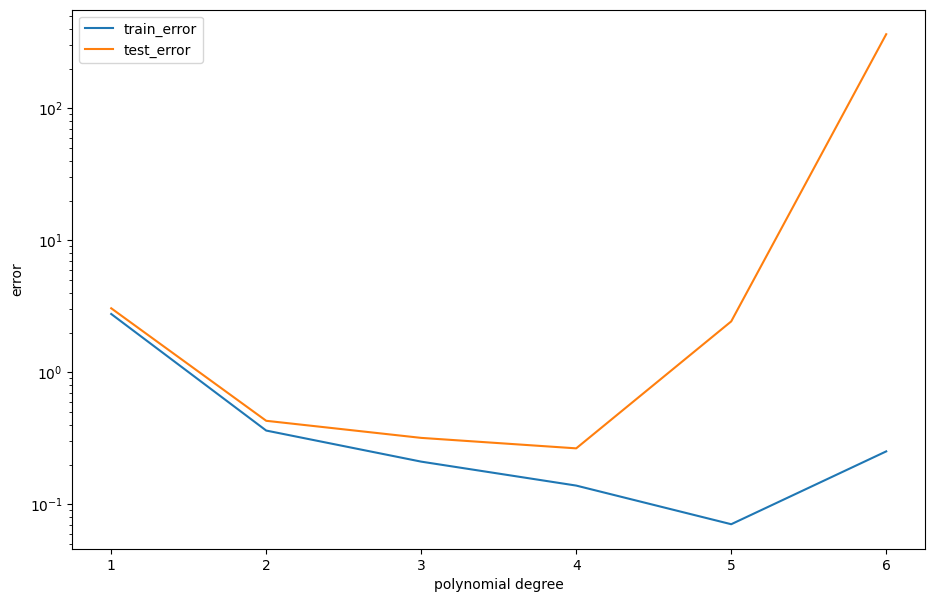

In [25]:
train_err = []
test_err = []

y = ad_df["Sales"]
X = ad_df.drop("Sales", axis=1)

kf = KFold(n_splits=10, random_state=None)  # We make 10 folds
model = LinearRegression(fit_intercept=False)

for f in range(1, 7):  # We try 6 different polynomial degrees
    train = []
    test = []
    for train_index, test_index in kf.split(X):  # We make for each fold
        poly = PolynomialFeatures(f)
        X_poly = poly.fit_transform(X)
        X_train, X_test = X_poly[train_index, :], X_poly[test_index, :]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        train.append(mean_squared_error(y_train, model.predict(X_train)))
        test.append(mean_squared_error(y_test, model.predict(X_test)))

    train_err.append(statistics.mean(train))
    test_err.append(statistics.mean(test))

fig = plt.figure(figsize=(11, 7))
plt.plot(range(1, 7), train_err, label="train_error")
plt.plot(range(1, 7), test_err, label="test_error")
plt.legend(fontsize=10)
plt.xlabel("polynomial degree")
plt.yscale(
    "log"
)  # Log scale because the error increases a lot and we don't see as much
plt.ylabel("error")
print(train_err)
print(test_err)